# Multiclass Iris Flower Cultivar Classifier

This notebook demonstrates the complete workflow for the project: dataset inspection, exploratory data analysis, leakage-safe preprocessing, OvR and Softmax Logistic Regression, five-fold hyperparameter tuning, evaluation, loss convergence, and coefficient interpretation.

Run the notebook from the project root, or use the commands in `README.md`.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from src.config import (
    DATASET_PATH,
    FEATURE_COLUMNS,
    TARGET_COLUMN,
    ID_COLUMN,
    FIGURES_DIR
)

from src.visualization import generate_all_visualizations

df = pd.read_csv(DATASET_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Project Root:", PROJECT_ROOT)

Dataset loaded successfully!
Dataset shape: (150, 6)
Project Root: /mnt/data/iris_project_work/iris-flower-classifier


In [2]:

# First five observations
display(df.head())

# Last five observations
display(df.tail())

# Dataset dimensions
print("Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())


,sample_id,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species_category
0,1,5.1,3.5,1.4,0.2,Setosa
1,2,4.9,3.0,1.4,0.2,Setosa
2,3,4.7,3.2,1.3,0.2,Setosa
3,4,4.6,3.1,1.5,0.2,Setosa
4,5,5.0,3.6,1.4,0.2,Setosa


,sample_id,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species_category
145,146,6.7,3.0,5.2,2.3,Virginica
146,147,6.3,2.5,5.0,1.9,Virginica
147,148,6.5,3.0,5.2,2.0,Virginica
148,149,6.2,3.4,5.4,2.3,Virginica
149,150,5.9,3.0,5.1,1.8,Virginica


Shape: (150, 6)

Columns:
['sample_id', 'sepal_length_cm', 'sepal_width_cm', 'petal_length_cm', 'petal_width_cm', 'species_category']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   sample_id         150 non-null    int64  
 1   sepal_length_cm   150 non-null    float64
 2   sepal_width_cm    150 non-null    float64
 3   petal_length_cm   150 non-null    float64
 4   petal_width_cm    150 non-null    float64
 5   species_category  150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB

Statistical Summary:


,sample_id,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.057333,3.758000,1.199333
std,43.445368,0.828066,0.435866,1.765298,0.762238
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


In [3]:

# Overall statistics
print("OVERALL FEATURE STATISTICS")
display(df[FEATURE_COLUMNS].agg(
    ["mean", "median", "std", "min", "max"]
))

# Species-wise statistics
print("\nSPECIES-WISE STATISTICS")

species_statistics = df.groupby(TARGET_COLUMN)[
    FEATURE_COLUMNS
].agg(["mean", "median", "std", "min", "max"])

display(species_statistics)


OVERALL FEATURE STATISTICS


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
mean,5.843333,3.057333,3.758000,1.199333
median,5.800000,3.000000,4.350000,1.300000
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
max,7.900000,4.400000,6.900000,2.500000



SPECIES-WISE STATISTICS


sepal_length_cm                   ... petal_width_cm          
                            mean median       std  ...            std  min  max
species_category                                   ...                         
Setosa                     5.006    5.0  0.352490  ...       0.105386  0.1  0.6
Versicolor                 5.936    5.9  0.516171  ...       0.197753  1.0  1.8
Virginica                  6.588    6.5  0.635880  ...       0.274650  1.4  2.5

[3 rows x 20 columns]

In [4]:

# Missing values
print("MISSING VALUES:")
display(df.isnull().sum())

# Total missing values
print("\nTotal missing values:", df.isnull().sum().sum())

# Duplicate observations excluding sample ID
duplicate_count = df.duplicated(
    subset=FEATURE_COLUMNS + [TARGET_COLUMN]
).sum()

print("\nDuplicate observations:", duplicate_count)

# Unique values
print("\nUNIQUE VALUES:")
display(df.nunique())

# Species distribution
print("\nSPECIES DISTRIBUTION:")
display(df[TARGET_COLUMN].value_counts())


MISSING VALUES:


sample_id           0
sepal_length_cm     0
sepal_width_cm      0
petal_length_cm     0
petal_width_cm      0
species_category    0
dtype: int64


Total missing values: 0

Duplicate observations: 1

UNIQUE VALUES:


sample_id           150
sepal_length_cm      35
sepal_width_cm       23
petal_length_cm      43
petal_width_cm       22
species_category      3
dtype: int64


SPECIES DISTRIBUTION:


species_category
Setosa        50
Versicolor    50
Virginica     50
Name: count, dtype: int64

In [5]:

# Calculate outliers using the IQR method

outlier_summary = {}

for feature in FEATURE_COLUMNS:

    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[feature] < lower_limit) |
        (df[feature] > upper_limit)
    ]

    outlier_summary[feature] = {
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Limit": lower_limit,
        "Upper Limit": upper_limit,
        "Outlier Count": len(outliers)
    }

outlier_df = pd.DataFrame(outlier_summary).T

display(outlier_df)


,Q1,Q3,IQR,Lower Limit,Upper Limit,Outlier Count
sepal_length_cm,5.1,6.4,1.3,3.15,8.35,0.0
sepal_width_cm,2.8,3.3,0.5,2.05,4.05,4.0
petal_length_cm,1.6,5.1,3.5,-3.65,10.35,0.0
petal_width_cm,0.3,1.8,1.5,-1.95,4.05,0.0


In [6]:

# Generate all project EDA visualizations

generate_all_visualizations(df)

print("\nEDA visualization generation completed.")


All EDA visualizations generated successfully!
Saved in: /mnt/data/iris_project_work/iris-flower-classifier/outputs/figures

EDA visualization generation completed.


## 4. Train-Test Partition and Preprocessing

The dataset is divided using a stratified 80:20 split. Scaling is placed inside each Scikit-learn pipeline so that the scaler is fitted only on the training portion of each fit or cross-validation fold.

In [7]:
from src.preprocessing import split_data
from src.train_model import build_models

X_train, X_test, y_train, y_test = split_data()
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Training class distribution:")
display(y_train.value_counts().sort_index())

ovr_pipeline, softmax_pipeline = build_models()
print("OvR pipeline:", ovr_pipeline)
print("Softmax pipeline:", softmax_pipeline)

Training shape: (120, 4)
Testing shape: (30, 4)
Training class distribution:


species_category
Setosa        40
Versicolor    40
Virginica     40
Name: count, dtype: int64

OvR pipeline: Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 OneVsRestClassifier(estimator=LogisticRegression(max_iter=1000,
                                                                  random_state=42)))])
Softmax pipeline: Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])


## 5. Hyperparameter Tuning

Both models are tuned using the same five-fold stratified cross-validation strategy and macro F1-score. The selected models are saved in the `models/` directory.

In [8]:
from src.hyperparameter_tuning import tune_models

ovr_search, softmax_search = tune_models()
print("OvR best parameters:", ovr_search.best_params_)
print("OvR best CV macro F1:", round(ovr_search.best_score_, 4))
print("Softmax best parameters:", softmax_search.best_params_)
print("Softmax best CV macro F1:", round(softmax_search.best_score_, 4))

Tuning OvR model...



Tuning Softmax model...

HYPERPARAMETER TUNING RESULTS
---------------------------------------------

OvR Best Parameters: {'classifier__estimator__C': 10}
OvR Best CV Macro F1: 0.9579707438530969

Softmax Best Parameters: {'classifier__C': 10}
Softmax Best CV Macro F1: 0.9663367569249923
OvR best parameters: {'classifier__estimator__C': 10}
OvR best CV macro F1: 0.958
Softmax best parameters: {'classifier__C': 10}
Softmax best CV macro F1: 0.9663


## 6. Held-Out Test Evaluation

The tuned models are evaluated on the same held-out test set. The evaluation module generates classification metrics, confusion matrices, ROC curves, precision-recall curves, and a model comparison CSV.

In [9]:
from src.evaluate_model import evaluate_models

evaluate_models()
comparison = pd.read_csv(PROJECT_ROOT / "models" / "model_comparison.csv")
display(comparison)


OvR MODEL EVALUATION
Accuracy: 0.9333
Precision (Macro): 0.9333
Precision (Weighted): 0.9333
Recall (Macro): 0.9333
Recall (Weighted): 0.9333
F1 (Macro): 0.9333
F1 (Weighted): 0.9333
ROC-AUC (Macro OvR): 0.9933

Classification Report:
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       0.90      0.90      0.90        10
   Virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30




Softmax MODEL EVALUATION
Accuracy: 1.0000
Precision (Macro): 1.0000
Precision (Weighted): 1.0000
Recall (Macro): 1.0000
Recall (Weighted): 1.0000
F1 (Macro): 1.0000
F1 (Weighted): 1.0000
ROC-AUC (Macro OvR): 1.0000

Classification Report:
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       1.00      1.00      1.00        10
   Virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30




FINAL MODEL COMPARISON
  Model  Accuracy  Precision Macro  Precision Weighted  Recall Macro  Recall Weighted  F1 Macro  F1 Weighted  ROC-AUC Macro OvR
    OvR  0.933333         0.933333            0.933333      0.933333         0.933333  0.933333     0.933333           0.993333
Softmax  1.000000         1.000000            1.000000      1.000000         1.000000  1.000000     1.000000           1.000000

Evaluation completed successfully!
Comparison saved in models/model_comparison.csv


,Model,Accuracy,Precision Macro,Precision Weighted,Recall Macro,Recall Weighted,F1 Macro,F1 Weighted,ROC-AUC Macro OvR
0,OvR,0.933333,0.933333,0.933333,0.933333,0.933333,0.933333,0.933333,0.993333
1,Softmax,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## 7. Loss Convergence Diagnostic

Scikit-learn's `LogisticRegression` does not expose its complete per-iteration loss history. The project's separate diagnostic explicitly minimizes the regularized OvR and Softmax objectives using L-BFGS-B. OvR's aggregate binary loss and Softmax categorical loss are different objectives, so their absolute values should not be treated as directly interchangeable.

LOSS CONVERGENCE COMPARISON
-------------------------------------------------------
Training samples: 120
Features: 4
Classes: ['Setosa', 'Versicolor', 'Virginica']
C: 10.0 (mean-loss L2 strength = 0.00083333)
OvR iterations (per class): [22, 17, 22]
OvR optimizer success (per class): [True, True, True]
OvR final aggregate loss: 0.57475387
Softmax iterations: 41
Softmax optimizer success: True
Softmax final loss: 0.09248732
Saved figure: /mnt/data/iris_project_work/iris-flower-classifier/outputs/figures/ovr_vs_softmax_loss_convergence.png
Saved history: /mnt/data/iris_project_work/iris-flower-classifier/models/loss_convergence_history.csv


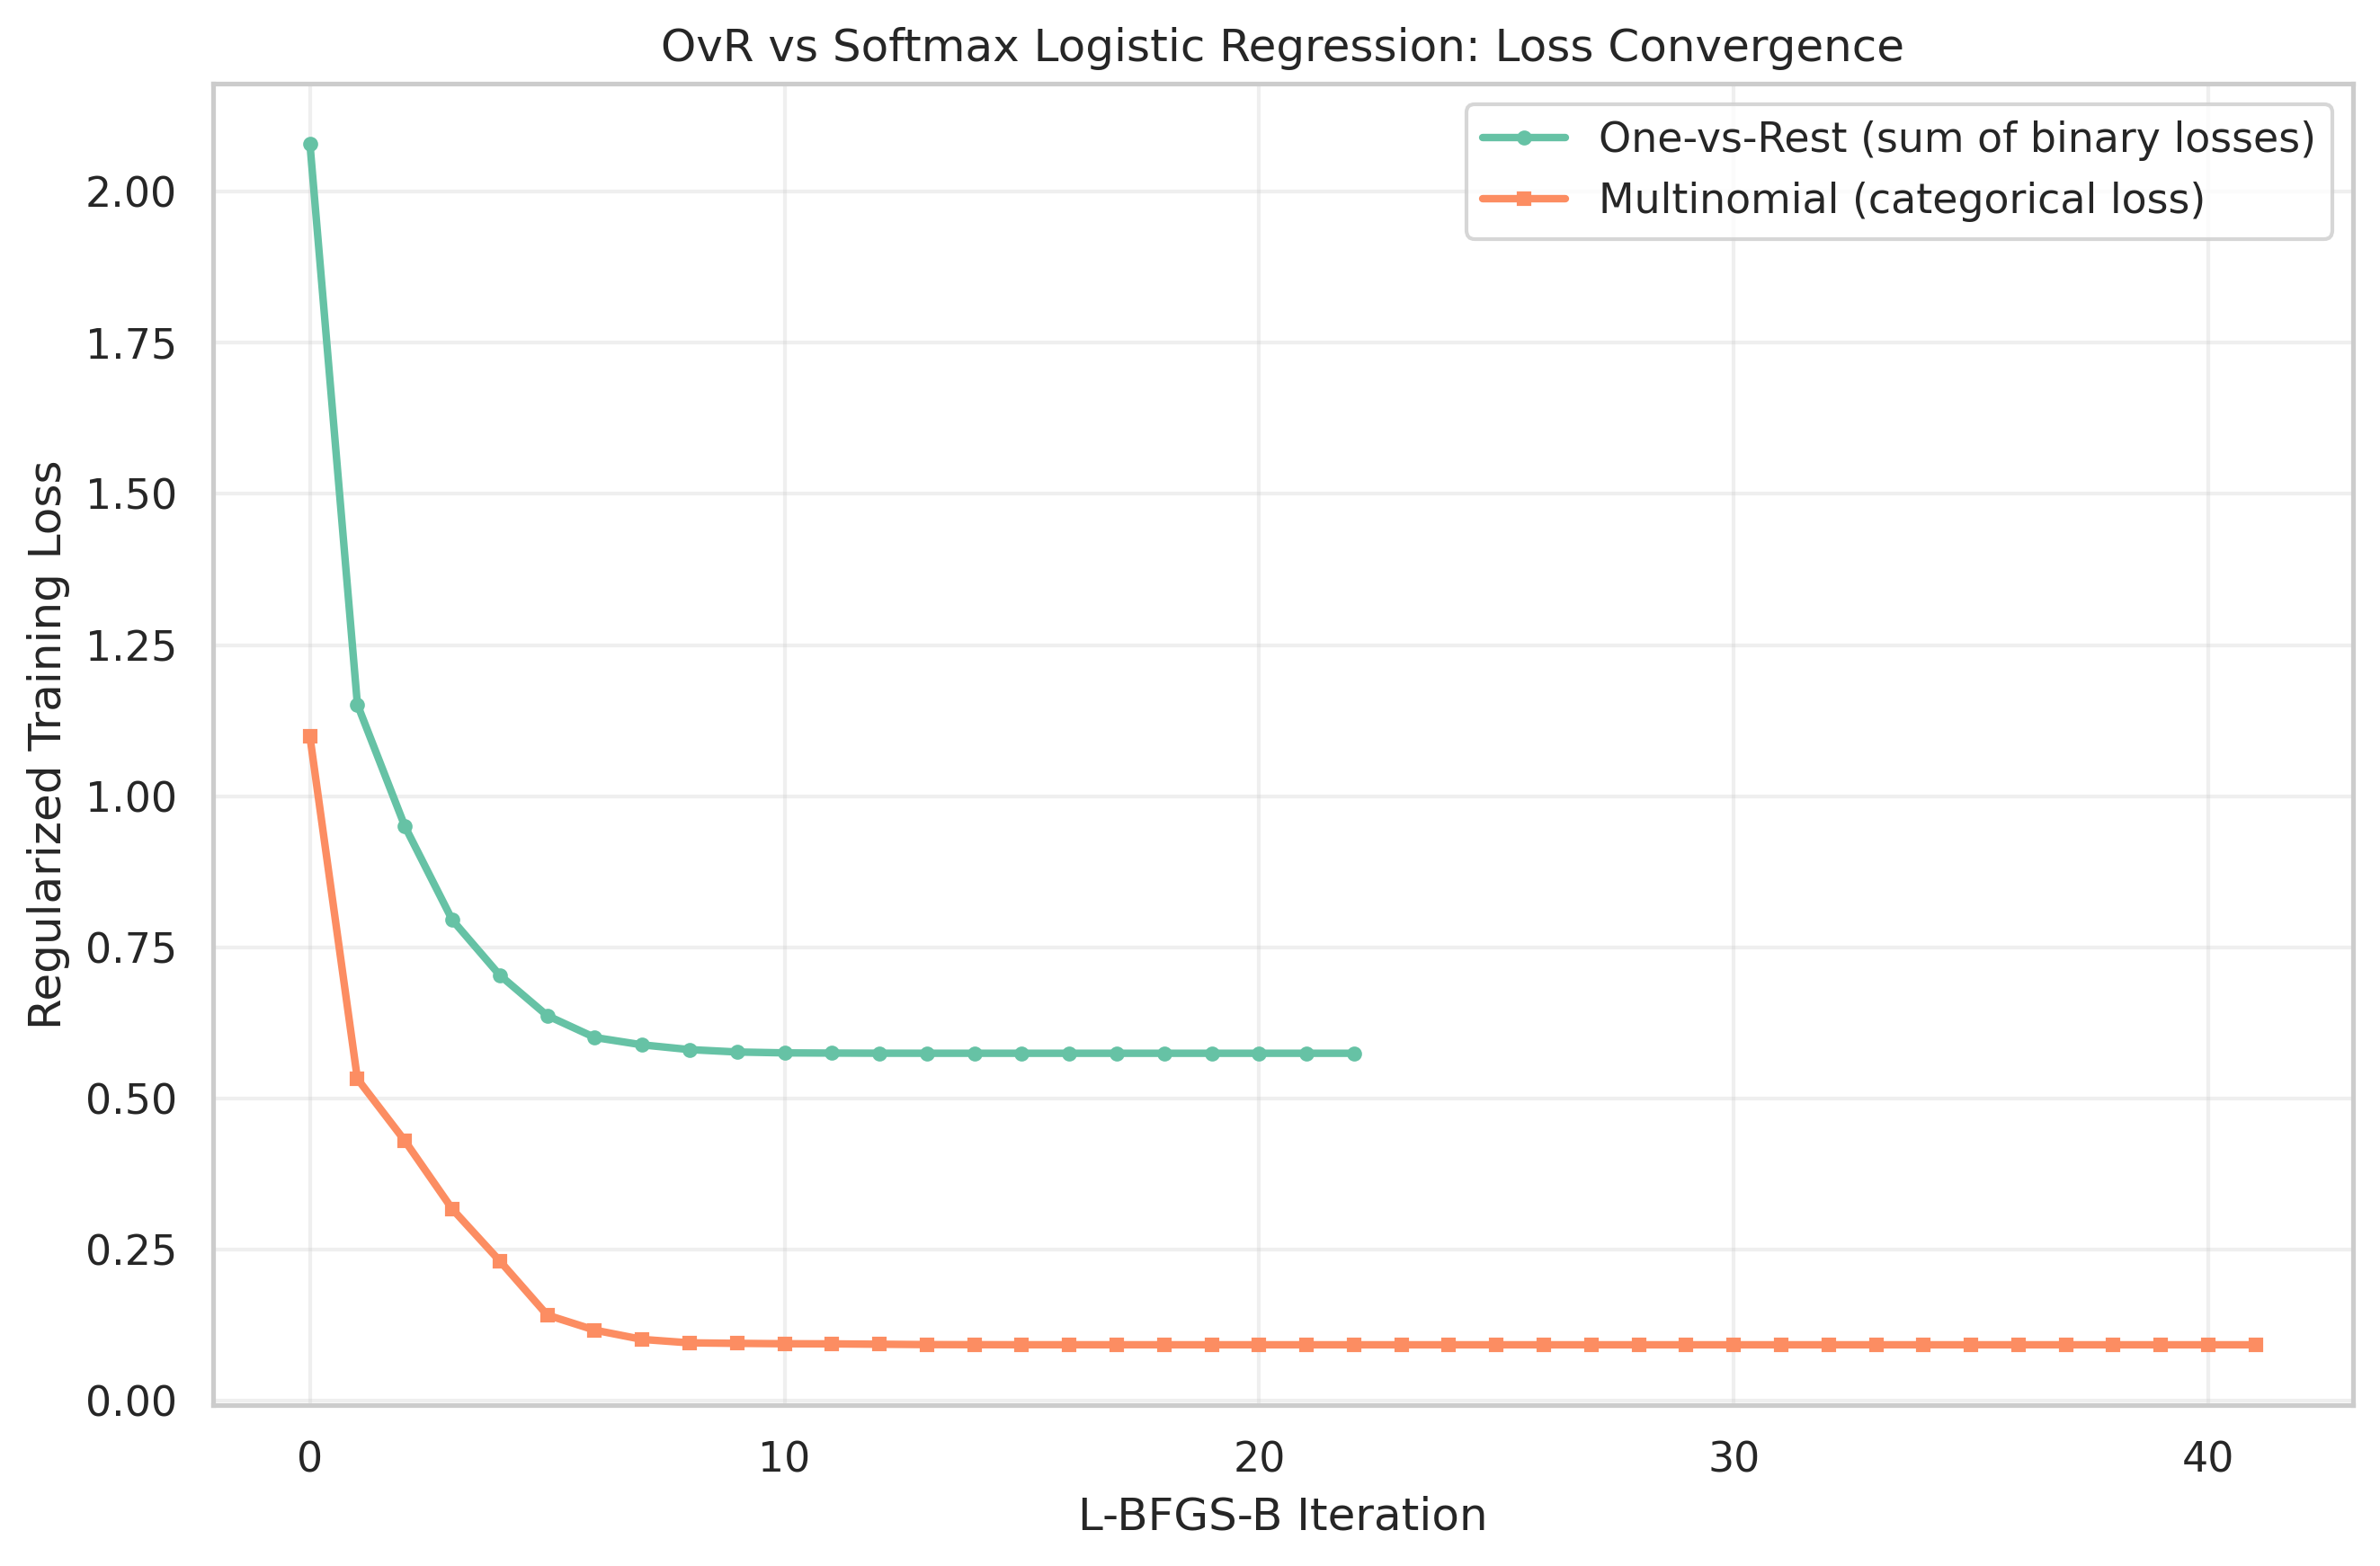

,Iteration,OvR_Aggregate_Binary_Cross_Entropy,Softmax_Categorical_Cross_Entropy
0,0,2.079442,1.098612
1,1,1.151766,0.532433
2,2,0.950296,0.429966
3,3,0.795242,0.317000
4,4,0.703943,0.231250


In [10]:
from IPython.display import Image, display
from src.loss_convergence import compare_loss_convergence

loss_history, loss_figure, loss_csv = compare_loss_convergence()
display(Image(filename=str(loss_figure)))
display(loss_history.head())

## 8. Learned Coefficient Interpretation

The following analysis extracts class-wise coefficients from the tuned pipelines. Since the input features are standardized, coefficient magnitudes represent changes in class log-odds/logits per one-standard-deviation increase in a feature. They are model-specific and are not causal effects.

FEATURE COEFFICIENT ANALYSIS
-------------------------------------------------------
Mean absolute coefficients (larger magnitude = stronger model influence):
Model               OvR  Softmax
Feature                         
petal_length_cm  3.4275   2.9705
petal_width_cm   3.4724   3.0849
sepal_length_cm  0.7378   1.2006
sepal_width_cm   1.3125   1.1480

Saved detailed coefficients: /mnt/data/iris_project_work/iris-flower-classifier/models/model_coefficients_by_species.csv
Saved summary: /mnt/data/iris_project_work/iris-flower-classifier/models/feature_coefficient_importance.csv
Saved comparison plot: /mnt/data/iris_project_work/iris-flower-classifier/outputs/figures/feature_coefficient_importance.png
Saved class-wise heatmaps: /mnt/data/iris_project_work/iris-flower-classifier/outputs/figures/model_coefficient_heatmaps.png


Model,OvR,Softmax
Feature,,
petal_length_cm,3.4275,2.9705
petal_width_cm,3.4724,3.0849
sepal_length_cm,0.7378,1.2006
sepal_width_cm,1.3125,1.1480


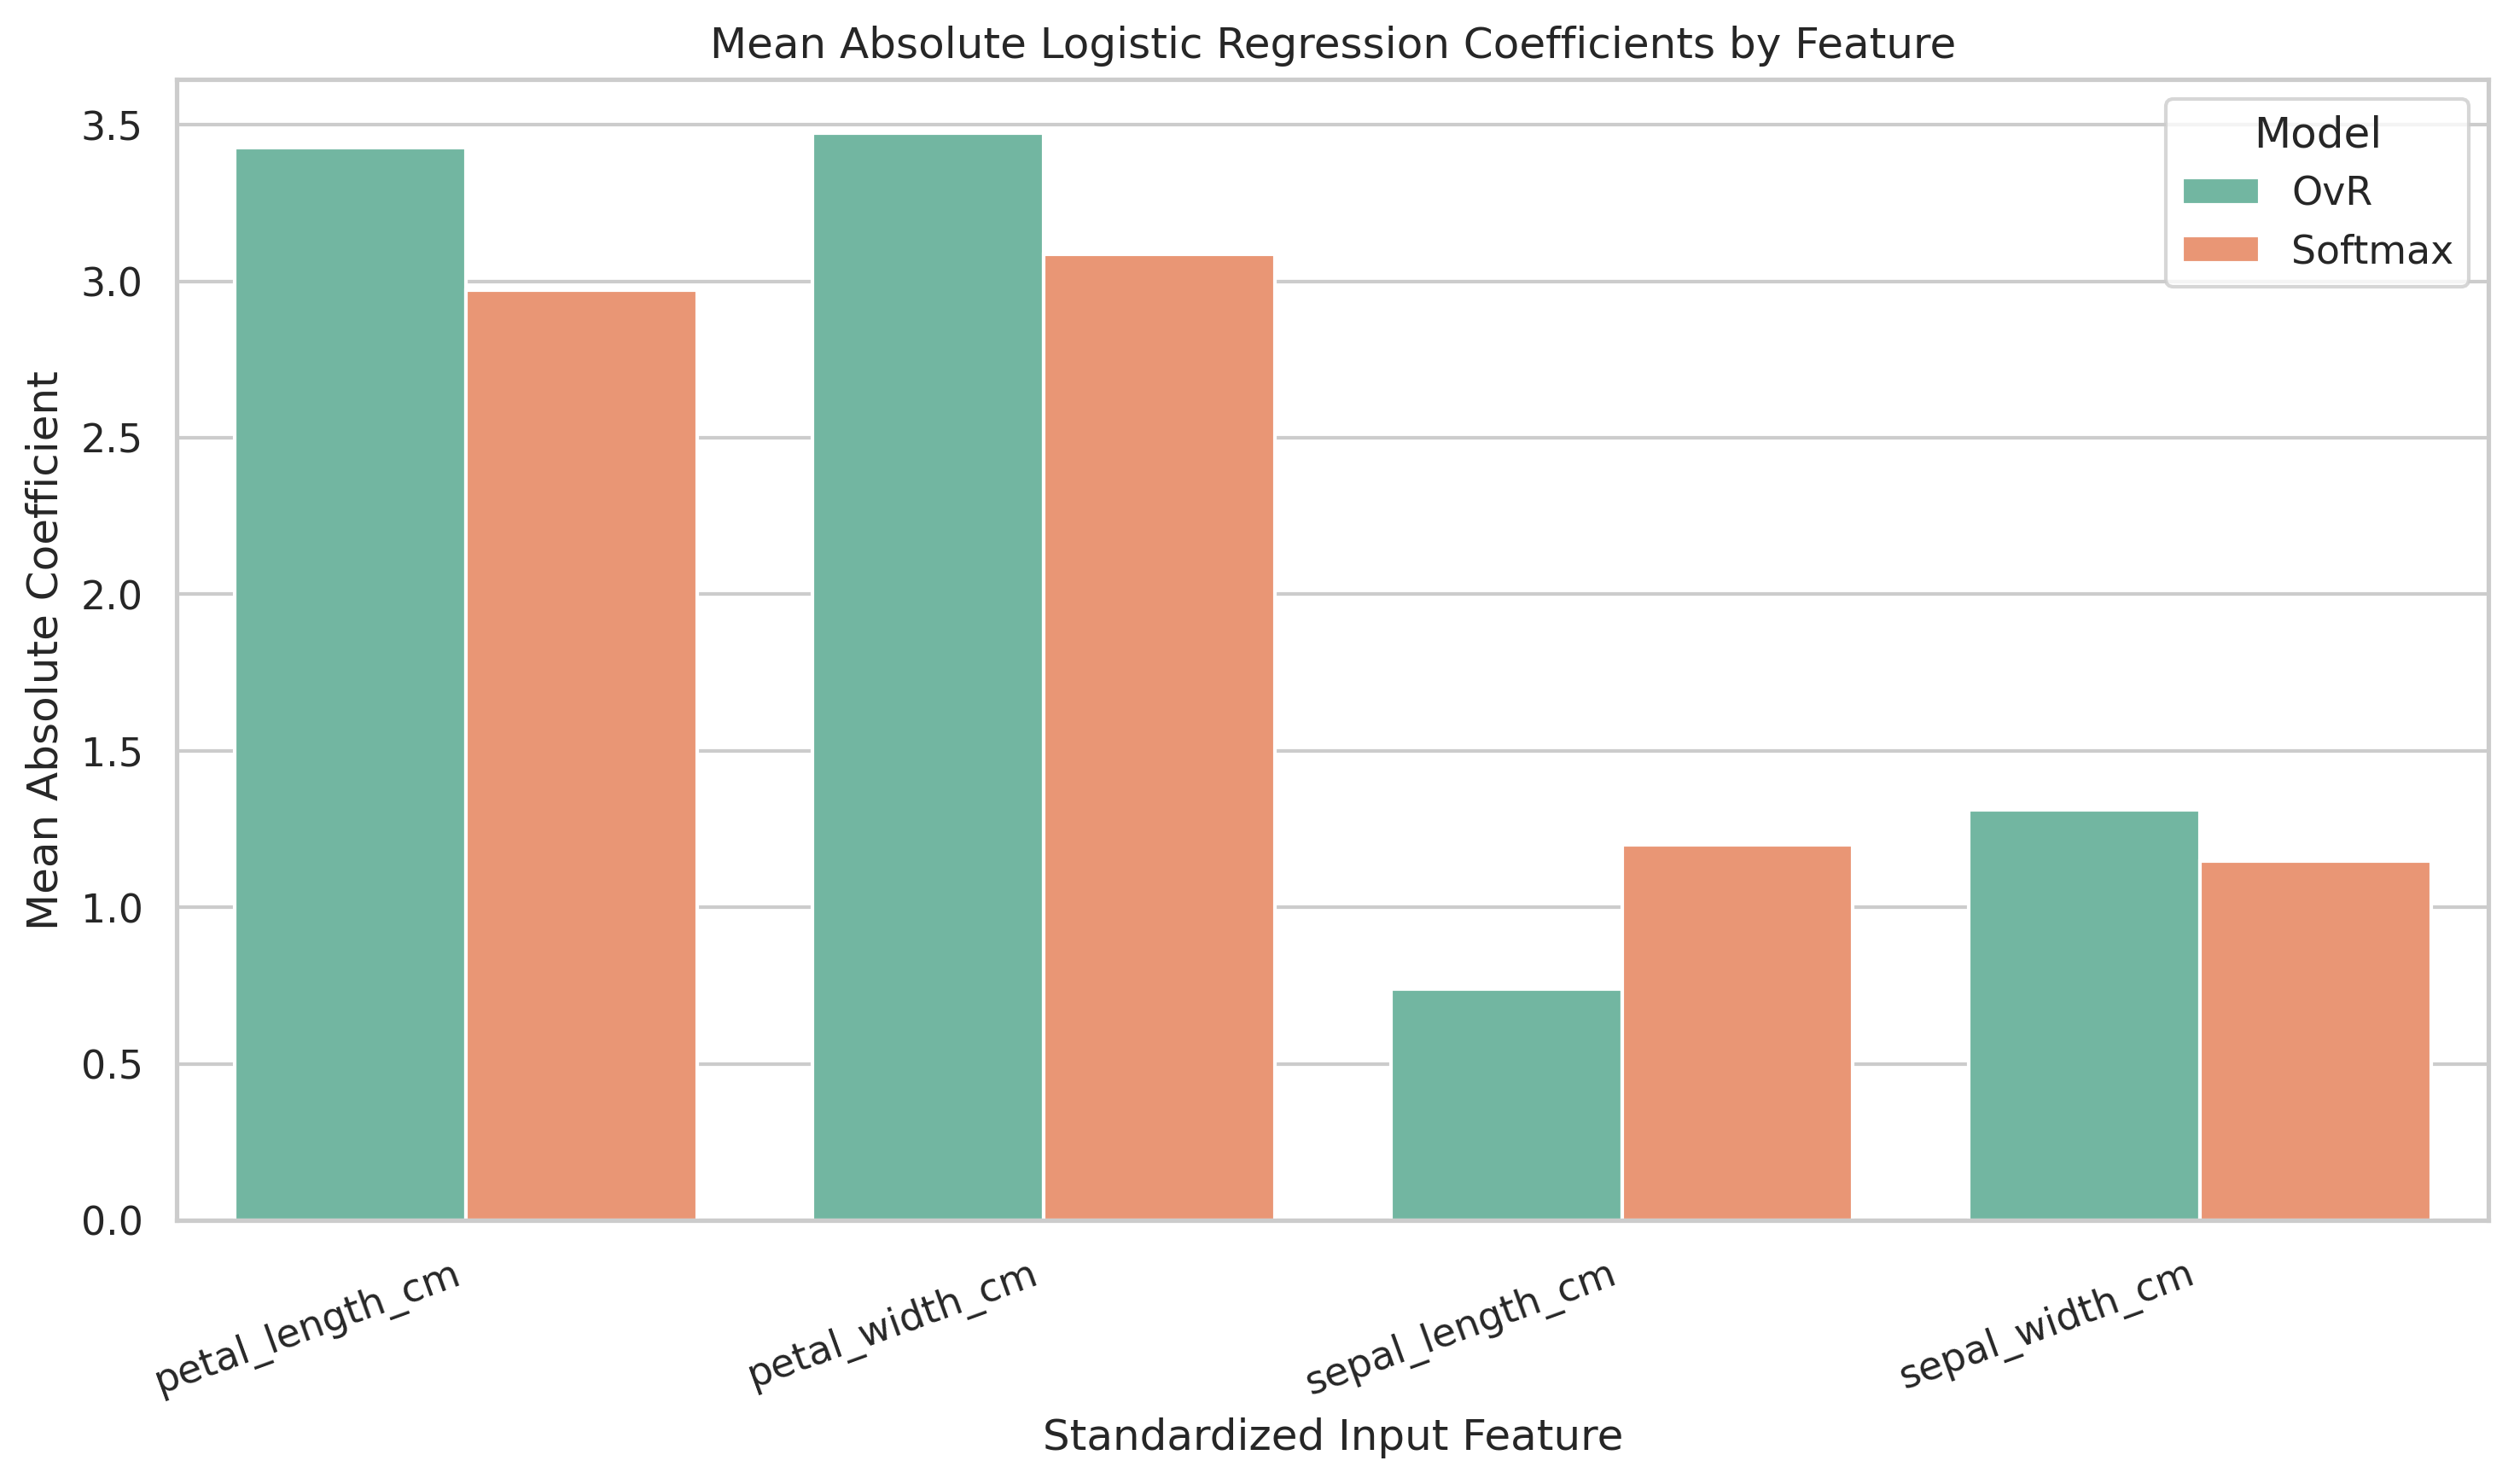

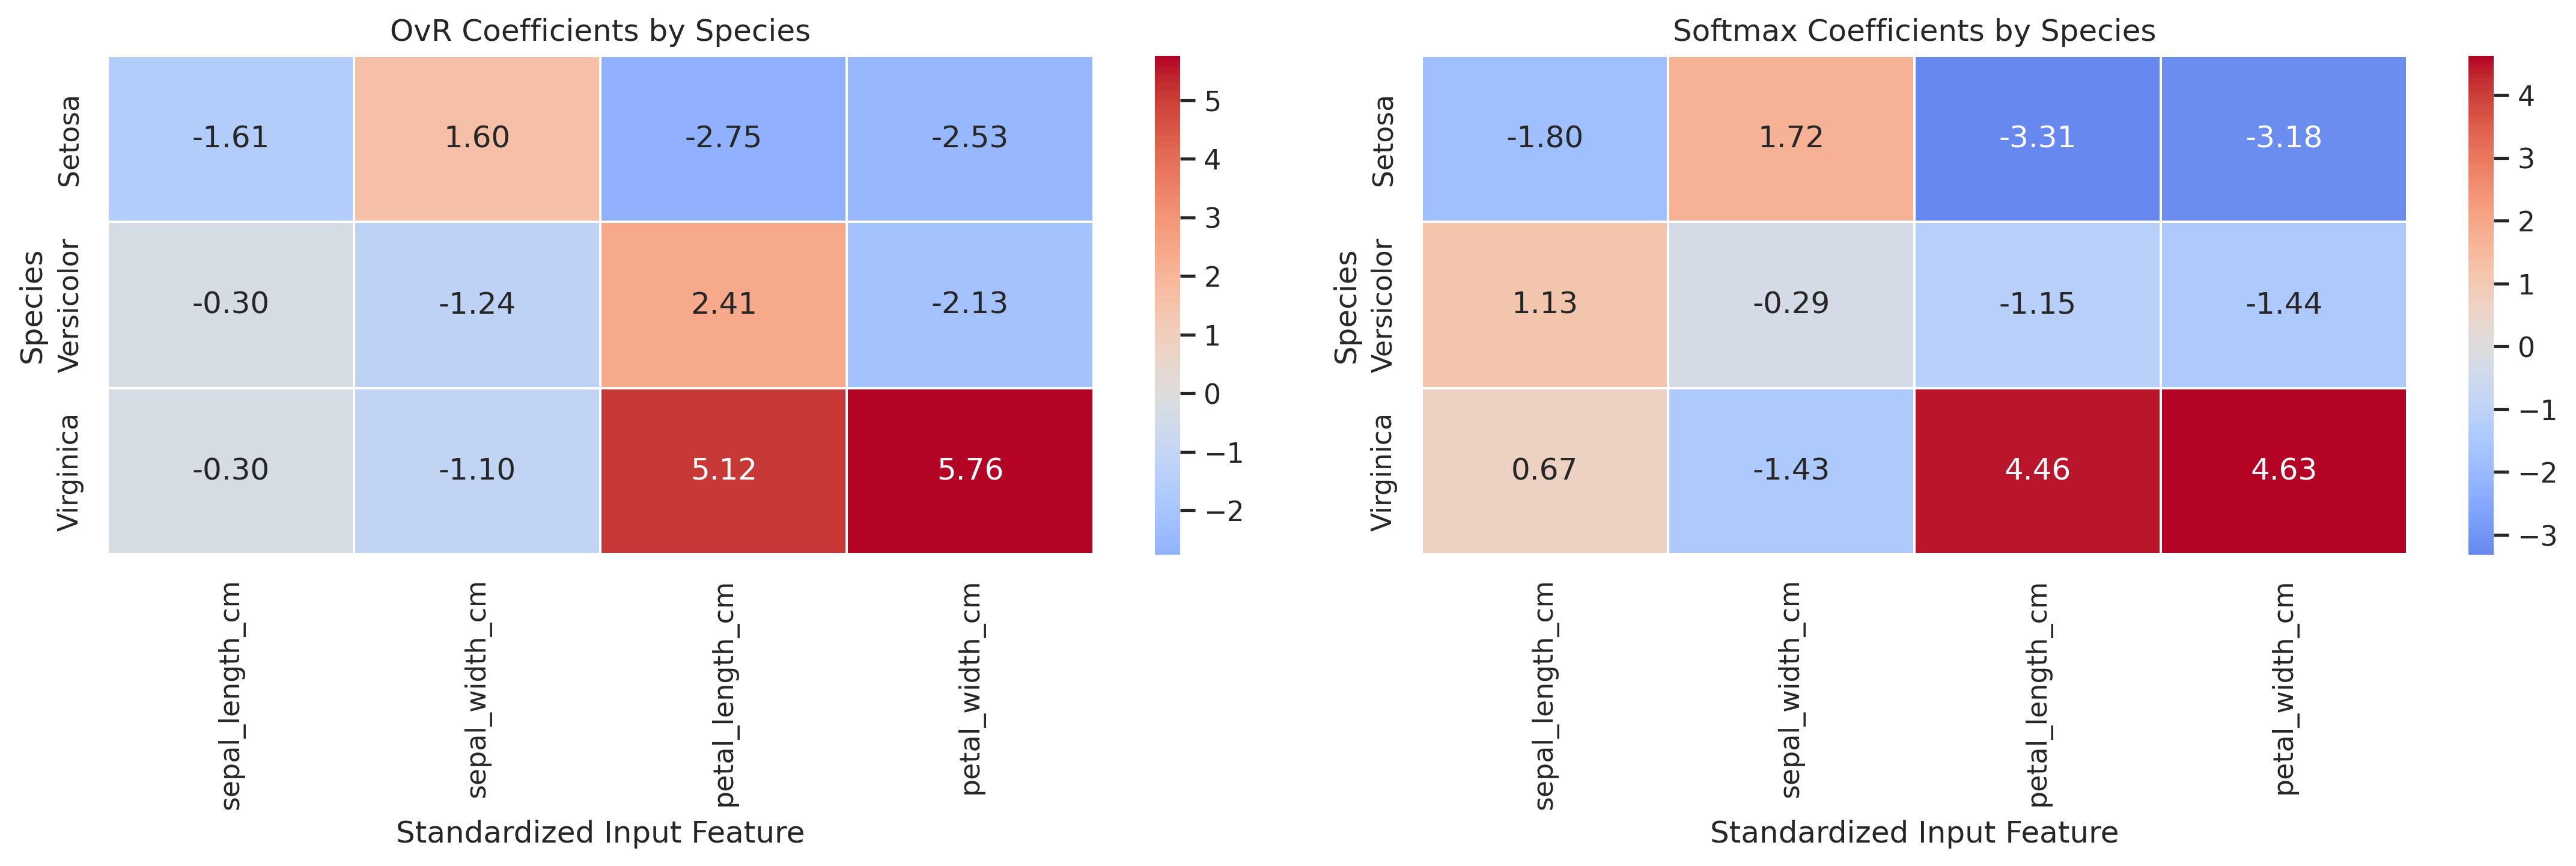

In [11]:
from src.feature_analysis import analyze_feature_coefficients

coefficient_details, coefficient_summary, coefficient_plot, coefficient_heatmaps = analyze_feature_coefficients()
display(coefficient_summary.pivot(
    index="Feature", columns="Model", values="MeanAbsoluteCoefficient"
).round(4))
display(Image(filename=str(coefficient_plot)))
display(Image(filename=str(coefficient_heatmaps)))

## 9. Final Notes

- The original dataset contains 150 observations and three balanced species classes.
- The main model evaluation uses four botanical features and a held-out test set of 30 observations.
- Two-feature decision-boundary plots are visualization-only models and should not be confused with the four-feature test evaluation.
- Run `python -m pytest -v` from the project root to execute the automated tests.